# Project 28: Traffic Pattern Discovery in Smart Cities
**Unsupervised learning | K-Means, DBSCAN and Ward hierarchical clustering**

This self-contained notebook uses a reproducible **simulated** dataset, not real sensor measurements. It includes chronological validation, held-out testing and an editable prototype. No external data upload is required. The optional real-data path is described in README.md. Run all cells in order.

## Imports and configuration

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
os.environ.setdefault('MKL_NUM_THREADS', '2')
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 42
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)

## Dataset: repeatable simulation or optional real CSV

In [2]:
def simulate_traffic():
    """Hourly counts at five fictional locations; not observed traffic."""
    rng = np.random.default_rng(SEED)
    sites = {'Central Junction': (180, 860, 750, 300),
             'IT Park Road': (100, 970, 920, 210),
             'Residential Road': (150, 430, 510, 190),
             'Market Street': (120, 430, 570, 500),
             'Ring Road': (260, 700, 720, 300)}
    rows = []
    for ts in pd.date_range('2025-01-06', periods=28*24, freq='h'):
        h = ts.hour
        weekend = ts.dayofweek >= 5
        for site, (base, am, pm, midday) in sites.items():
            # Smooth morning/evening peaks with site-specific intensity.
            peak = am*np.exp(-((h-8)/2.0)**2) + pm*np.exp(-((h-18)/2.5)**2)
            daytime = midday*np.exp(-((h-13)/4)**2)
            if weekend:
                peak *= 0.50 if site != 'Market Street' else 0.85
                daytime *= 1.25 if site == 'Market Street' else 0.85
            mean = base + peak + daytime
            volume = max(0, round(mean + rng.normal(0, 35 + 0.07*mean)))
            if rng.random() < 0.012:  # uncommon disruptions
                volume = round(volume * rng.uniform(0.2, 1.7))
            rows.append((ts, site, volume))
    raw = pd.DataFrame(rows, columns=['timestamp','location','traffic_volume'])
    # Introduce a few missing readings and exact duplicates to demonstrate cleaning.
    raw.loc[rng.choice(raw.index, 20, replace=False), 'traffic_volume'] = np.nan
    return pd.concat([raw, raw.sample(12, random_state=SEED)], ignore_index=True)

# Set DATA_FILE to a normalized CSV path to use your own data (see README).
DATA_FILE = None
if __name__ == '__main__' and 'ipykernel' not in sys.modules and len(sys.argv) > 1:
    DATA_FILE = sys.argv[1]
raw = pd.read_csv(DATA_FILE) if DATA_FILE else simulate_traffic()
source_name = 'User-supplied CSV' if DATA_FILE else 'Simulated traffic (not measured)'
if not DATA_FILE:
    raw.to_csv('traffic_dataset.csv', index=False)
print('Source:', source_name, '| Raw rows:', len(raw))
print(raw.head().to_string(index=False))

Source: Simulated traffic (not measured) | Raw rows: 3372
 timestamp         location  traffic_volume
2025-01-06 Central Junction           195.0
2025-01-06     IT Park Road           132.0
2025-01-06 Residential Road            61.0
2025-01-06    Market Street           126.0
2025-01-06        Ring Road           259.0


## Cleaning and chronological split

In [3]:
def clean_traffic(raw):
    data = raw[['timestamp','location','traffic_volume']].copy()
    data['timestamp'] = pd.to_datetime(data['timestamp'], errors='coerce')
    data['traffic_volume'] = pd.to_numeric(data['traffic_volume'], errors='coerce')
    data['location'] = data['location'].astype('string').str.strip()
    data = data.dropna().drop_duplicates()
    data = data[(data.traffic_volume >= 0) & (data.location != '') & np.isfinite(data.traffic_volume)]
    # If a location-hour has conflicting counts, average rather than double-count.
    data = data.groupby(['timestamp','location'], as_index=False).traffic_volume.mean()
    data = data.sort_values(['timestamp','location']).reset_index(drop=True)
    data['hour'] = data.timestamp.dt.hour
    data['weekend'] = (data.timestamp.dt.dayofweek >= 5).astype(int)
    return data

data = clean_traffic(raw)
days = data.timestamp.dt.normalize().drop_duplicates().sort_values().to_numpy()
if len(days) < 10:
    raise ValueError('Use at least 10 distinct dates for the chronological split.')
cut1, cut2 = days[int(len(days)*.65)], days[int(len(days)*.82)]
train = data[data.timestamp < cut1].copy()
val = data[(data.timestamp >= cut1) & (data.timestamp < cut2)].copy()
test = data[data.timestamp >= cut2].copy()
# Bound expensive clustering to a repeatable sample of at most 3500 training rows.
if len(train) > 3500:
    train = train.sample(3500, random_state=SEED).sort_values('timestamp')
if len(val) > 2000: val = val.sample(2000, random_state=SEED)
if len(test) > 2000: test = test.sample(2000, random_state=SEED)
print('Clean rows:', len(data), '| removed:', len(raw)-len(data))
print('Train / validation / test:', len(train), len(val), len(test))
print('Validation starts:', pd.Timestamp(cut1).date(), '| Test starts:', pd.Timestamp(cut2).date())
print('Locations:', sorted(data.location.unique()))

Clean rows: 3340 | removed: 32
Train / validation / test: 2145 478 717
Validation starts: 2025-01-24 | Test starts: 2025-01-28
Locations: ['Central Junction', 'IT Park Road', 'Market Street', 'Residential Road', 'Ring Road']


## Exploratory analysis

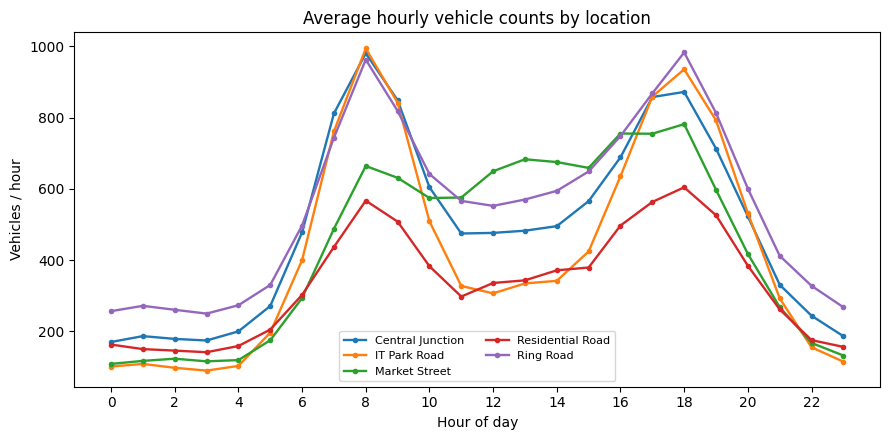

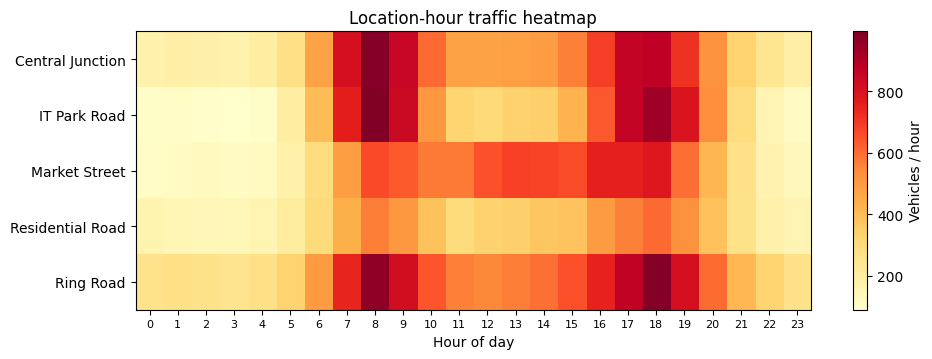

In [4]:
def save_plot(name):
    plt.tight_layout(); plt.savefig(OUT/name, dpi=150, bbox_inches='tight'); plt.show(); plt.close()
profile = data.groupby(['hour','location']).traffic_volume.mean().unstack()
profile.plot(figsize=(9,4.5), marker='.', linewidth=1.7)
plt.title('Average hourly vehicle counts by location'); plt.ylabel('Vehicles / hour'); plt.xlabel('Hour of day'); plt.xticks(range(0,24,2)); plt.legend(fontsize=8, ncol=2); save_plot('hourly_traffic.png')
heat = data.pivot_table(index='location',columns='hour',values='traffic_volume',aggfunc='mean')
plt.figure(figsize=(10,3.7)); plt.imshow(heat, aspect='auto', cmap='YlOrRd'); plt.yticks(range(len(heat)),heat.index); plt.xticks(range(len(heat.columns)),heat.columns,fontsize=8); plt.xlabel('Hour of day'); plt.colorbar(label='Vehicles / hour'); plt.title('Location-hour traffic heatmap'); save_plot('traffic_heatmap.png')

## Feature engineering and scaling

In [5]:
# Weight volume strongly, encode circular time, and include modest location/weekend effects.
scaler = StandardScaler().fit(train[['traffic_volume']])
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(train[['location']])
def features(frame):
    angle = 2*np.pi*frame.hour.to_numpy()/24
    return np.column_stack([scaler.transform(frame[['traffic_volume']]),
        .40*np.sin(angle), .40*np.cos(angle), .30*frame.weekend.to_numpy(),
        .25*encoder.transform(frame[['location']])])
Xtr, Xv, Xt = (features(f) for f in (train,val,test))
print('Model feature dimensions:', Xtr.shape[1])

Model feature dimensions: 9


## Three clustering algorithms, baseline and validation

                 algorithm                      parameters  clusters  coverage  silhouette  davies_bouldin   score  eligible
Volume tertiles (baseline)                              {}         3    1.0000      0.3325          0.9949  0.3325      True
                   K-Means                        {'k': 2}         2    1.0000      0.4616          0.8159  0.4616      True
       Hierarchical (Ward)                        {'k': 2}         2    1.0000      0.4615          0.8165  0.4615      True
                    DBSCAN {'eps': 0.25, 'min_samples': 8}        30    0.8661     -0.0511          1.9814 -0.0443      True
Selected ML model: K-Means {'k': 2}


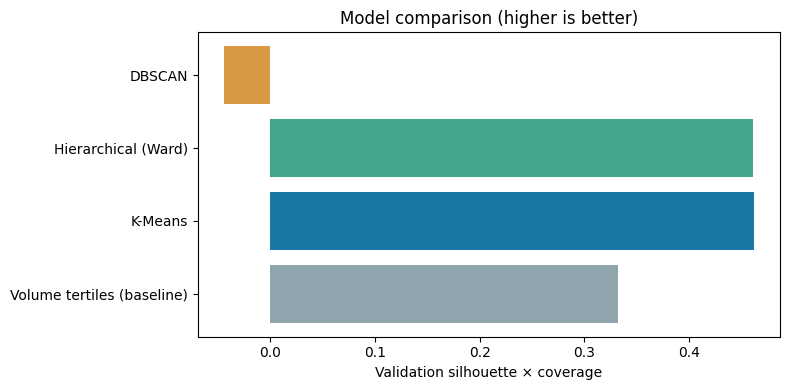

In [6]:
def metrics(X, labels):
    labels = np.asarray(labels); mask = labels != -1
    n = len(np.unique(labels[mask])); coverage = float(mask.mean())
    if n < 2 or mask.sum() <= n:
        return dict(clusters=n, coverage=coverage, silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan, score=np.nan)
    s = silhouette_score(X[mask], labels[mask], sample_size=min(1500,mask.sum()), random_state=SEED)
    return dict(clusters=n, coverage=coverage, silhouette=s,
        davies_bouldin=davies_bouldin_score(X[mask],labels[mask]),
        calinski_harabasz=calinski_harabasz_score(X[mask],labels[mask]), score=s*coverage)

def fit_candidate(kind, params):
    if kind == 'K-Means':
        model = KMeans(n_clusters=params['k'], n_init=10, random_state=SEED).fit(Xtr)
        labels = model.labels_; assign = model.predict
    elif kind == 'Hierarchical (Ward)':
        model = AgglomerativeClustering(n_clusters=params['k'], linkage='ward').fit(Xtr)
        labels = model.labels_
        ids = np.unique(labels); centers = np.array([Xtr[labels==i].mean(axis=0) for i in ids])
        def assign(X): return ids[pairwise_distances_argmin_min(X, centers)[0]]
    elif kind == 'DBSCAN':
        model = DBSCAN(eps=params['eps'], min_samples=params['min_samples']).fit(Xtr)
        labels = model.labels_
        core_ids = model.core_sample_indices_
        if len(core_ids):
            nn = NearestNeighbors(n_neighbors=1).fit(Xtr[core_ids])
            def assign(X):
                dist, idx = nn.kneighbors(X)
                return np.where(dist[:,0] <= model.eps, labels[core_ids[idx[:,0]]], -1)
        else:
            def assign(X): return np.full(len(X), -1, dtype=int)
    else: # simple fixed volume groups, based only on training quantiles
        q = np.quantile(Xtr[:,0], [1/3,2/3]); assign = lambda X: np.digitize(X[:,0],q)
        labels = assign(Xtr)
    return labels, assign

specs = [('Volume tertiles (baseline)',{})]
for k in range(2,7):
    specs.extend([('K-Means',{'k':k}),('Hierarchical (Ward)',{'k':k})])
for eps in [.10,.15,.20,.25,.30,.40,.50]:
    for ms in [8,16]: specs.append(('DBSCAN',{'eps':eps,'min_samples':ms}))
rows=[]; fitted={}
for i,(kind,params) in enumerate(specs):
    labels, assign = fit_candidate(kind,params)
    fitted[i] = (labels,assign)
    v = metrics(Xv,assign(Xv))
    rows.append(dict(candidate=i,algorithm=kind,parameters=str(params),**v))
search = pd.DataFrame(rows)
search['eligible'] = (search.coverage >= .80) & search.silhouette.notna() & (search.clusters >= 2)
search.to_csv(OUT/'validation_grid.csv',index=False)
# Compare the best eligible candidate from each method. If none, report best diagnostic candidate.
selected=[]
for kind, group in search.groupby('algorithm',sort=False):
    good = group[group.eligible]
    pool = good if len(good) else group
    selected.append(pool.sort_values(['score','coverage'],ascending=False,na_position='last').iloc[0])
comparison=pd.DataFrame(selected).reset_index(drop=True)
comparison.to_csv(OUT/'model_comparison.csv',index=False)
print(comparison[['algorithm','parameters','clusters','coverage','silhouette','davies_bouldin','score','eligible']].round(4).to_string(index=False))
valid = search[search.eligible & (search.algorithm != 'Volume tertiles (baseline)')]
if valid.empty: raise RuntimeError('No eligible ML model; inspect data and grid.')
winner=valid.sort_values('score',ascending=False).iloc[0]
train_labels, predict = fitted[int(winner.candidate)]
print('Selected ML model:',winner.algorithm,winner.parameters)
plt.figure(figsize=(8,4)); plot=comparison.set_index('algorithm'); plt.barh(plot.index,plot.score.fillna(0),color=['#90a4ae','#1976a5','#43a68c','#d99844']); plt.xlabel('Validation silhouette × coverage'); plt.title('Model comparison (higher is better)'); save_plot('model_comparison.png')

## Untouched test evaluation and interpretation

        split  clusters  coverage  silhouette  davies_bouldin  calinski_harabasz  score
        train         2       1.0      0.4858          0.7700          3164.3345 0.4858
         test         2       1.0      0.4665          0.7963           995.2230 0.4665
test baseline         3       1.0      0.3390          0.9792           832.3923 0.3390
 cluster  records  mean_volume  min_volume  max_volume  weekend_share  peak_hour  common_location                pattern
       0      959       712.78       462.0      1391.0           0.16          8        Ring Road Highest-volume pattern
       1     1186       247.51         0.0       485.0           0.27          0 Residential Road  Lowest-volume pattern
Test noise/unmatched: 0


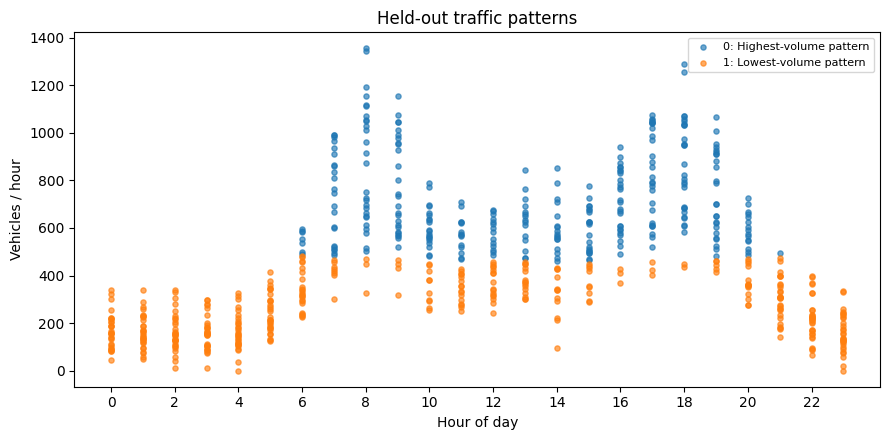

Smallest centroid-margin examples (not ground-truth errors):
          timestamp         location  traffic_volume                pattern  centroid_margin
2025-01-28 14:00:00     IT Park Road           461.0 Highest-volume pattern            0.007
2025-01-30 06:00:00 Central Junction           491.0 Highest-volume pattern            0.015
2025-01-31 15:00:00     IT Park Road           464.0 Highest-volume pattern            0.017
2025-01-31 07:00:00    Market Street           486.0 Highest-volume pattern            0.018
2025-01-31 13:00:00 Residential Road           458.0  Lowest-volume pattern            0.019


In [7]:
# Assign final test data using the selected training model. No retuning on test.
test_labels = predict(Xt)
train_stats = metrics(Xtr,train_labels); test_stats = metrics(Xt,test_labels)
baseline_row = search[search.algorithm=='Volume tertiles (baseline)'].iloc[0]
base_test = metrics(Xt,fitted[int(baseline_row.candidate)][1](Xt))
final_metrics=pd.DataFrame([{'split':'train',**train_stats},{'split':'test',**test_stats},{'split':'test baseline',**base_test}])
final_metrics.to_csv(OUT/'final_metrics.csv',index=False)
print(final_metrics.round(4).to_string(index=False))
train_out=train.assign(cluster=train_labels)
summary=train_out.groupby('cluster').agg(records=('traffic_volume','size'),mean_volume=('traffic_volume','mean'),min_volume=('traffic_volume','min'),max_volume=('traffic_volume','max'),weekend_share=('weekend','mean'),peak_hour=('hour',lambda x:int(x.mode().iloc[0])),common_location=('location',lambda x:x.mode().iloc[0])).reset_index()
# Semantic names are relative traffic-volume ranks, not measured congestion.
ranked=summary[summary.cluster!=-1].sort_values('mean_volume').cluster.tolist()
names={c:f'Volume rank {i+1}/{len(ranked)}' for i,c in enumerate(ranked)}
if ranked: names[ranked[0]]='Lowest-volume pattern'; names[ranked[-1]]='Highest-volume pattern'
names[-1]='Noise / unmatched'
summary['pattern']=summary.cluster.map(names)
summary.to_csv(OUT/'cluster_profiles.csv',index=False)
print(summary.round(2).to_string(index=False))
print('Test noise/unmatched:',int((test_labels==-1).sum()))
test_out=test.assign(cluster=test_labels,pattern=pd.Series(test_labels,index=test.index).map(names))
test_out.to_csv(OUT/'test_assignments.csv',index=False)
plt.figure(figsize=(9,4.5))
for c,g in test_out.groupby('cluster'):
    plt.scatter(g.hour,g.traffic_volume,s=14,alpha=.65,label=f'{c}: {names[c]}')
plt.xlabel('Hour of day'); plt.ylabel('Vehicles / hour'); plt.title('Held-out traffic patterns'); plt.xticks(range(0,24,2)); plt.legend(fontsize=8); save_plot('traffic_clusters.png')
# Error analysis: nearest competing cluster centroid margin, for diagnostic use only.
centers=np.array([Xtr[train_labels==c].mean(axis=0) for c in ranked])
from sklearn.metrics import pairwise_distances
if len(centers)>=2:
    distances=np.sort(pairwise_distances(Xt,centers),axis=1)
    gap=distances[:,1]-distances[:,0]
    ambiguous=test_out.assign(centroid_margin=gap).sort_values('centroid_margin').head(10)
    ambiguous.to_csv(OUT/'ambiguous_examples.csv',index=False)
    print('Smallest centroid-margin examples (not ground-truth errors):')
    print(ambiguous[['timestamp','location','traffic_volume','pattern','centroid_margin']].round(3).head(5).to_string(index=False))

## Working prototype: classify a new observed traffic record

In [8]:
def discover_pattern(location, hour, vehicle_count, weekend=False):
    if location not in encoder.categories_[0]:
        raise ValueError('Unknown location: select one of the training locations.')
    if int(hour)!=hour or not 0<=hour<=23 or not np.isfinite(vehicle_count) or vehicle_count<0:
        raise ValueError('Hour must be an integer 0–23 and vehicle count must be finite and nonnegative.')
    f=pd.DataFrame({'location':[location],'hour':[hour],'traffic_volume':[vehicle_count],'weekend':[int(bool(weekend))]})
    c=int(predict(features(f))[0]); return {'cluster':c,'pattern':names.get(c,'Unmatched'), 'vehicles_per_hour':vehicle_count}

# Change these inputs, then run this cell again to try the prototype.
location = encoder.categories_[0][0]
hour = 8
vehicle_count = 950
weekend = False
print('Sample peak:', discover_pattern(location,hour,vehicle_count,weekend))
print('Sample night:', discover_pattern(location,2,110,False))
print('Complete. Outputs saved to',OUT.resolve())

Sample peak: {'cluster': 0, 'pattern': 'Highest-volume pattern', 'vehicles_per_hour': 950}
Sample night: {'cluster': 1, 'pattern': 'Lowest-volume pattern', 'vehicles_per_hour': 110}
Complete. Outputs saved to /mnt/data/Project28/outputs


## Conclusion
Compare the validation results, then inspect the held-out cluster profiles and borderline records. Silhouette measures separation, not accuracy. High volume is not necessarily congestion. Because the data are simulated, real-world validation is required before operational use.